Training samples: 11314
Testing samples: 7532
Training shape: (11314, 101322)
Testing shape: (7532, 101322)
Multinomial Naive Bayes
-----------------------
Accuracy: 0.6343600637280935
Weighted F1 Score: 0.6095621937424516

Classification Report
                          precision    recall  f1-score   support

             alt.atheism       0.65      0.30      0.41       319
           comp.graphics       0.58      0.69      0.63       389
 comp.os.ms-windows.misc       0.40      0.01      0.01       394
comp.sys.ibm.pc.hardware       0.53      0.72      0.61       392
   comp.sys.mac.hardware       0.74      0.56      0.64       385
          comp.windows.x       0.56      0.81      0.66       395
            misc.forsale       0.85      0.69      0.76       390
               rec.autos       0.82      0.70      0.76       396
         rec.motorcycles       0.91      0.62      0.73       398
      rec.sport.baseball       0.94      0.74      0.83       397
        rec.sport.hockey   

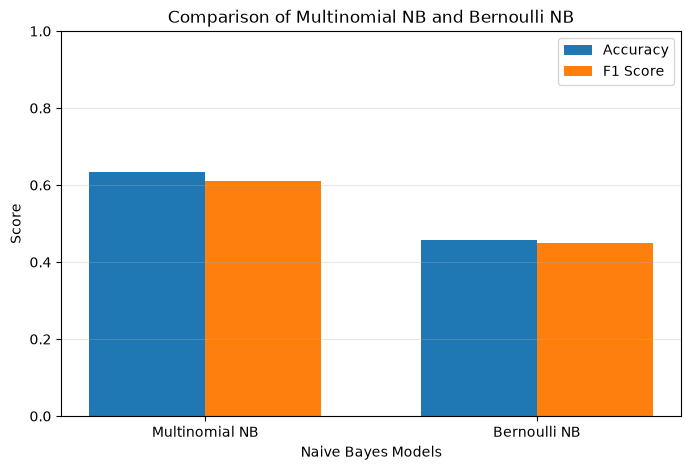

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, f1_score, classification_report

train_data = fetch_20newsgroups(subset='train', remove=('headers', 'footers', 'quotes'))
test_data = fetch_20newsgroups(subset='test', remove=('headers', 'footers', 'quotes'))

X_train = train_data.data
X_test = test_data.data
y_train = train_data.target
y_test = test_data.target

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


count_vectorizer = CountVectorizer(stop_words='english')
X_train_count = count_vectorizer.fit_transform(X_train)
X_test_count = count_vectorizer.transform(X_test)
print("Training shape:", X_train_count.shape)
print("Testing shape:", X_test_count.shape)


binary_vectorizer = CountVectorizer(binary=True, stop_words='english')
X_train_binary = binary_vectorizer.fit_transform(X_train)
X_test_binary = binary_vectorizer.transform(X_test)

mnb = MultinomialNB()
mnb.fit(X_train_count, y_train)
y_pred_mnb = mnb.predict(X_test_count)

bnb = BernoulliNB()
bnb.fit(X_train_binary, y_train)
y_pred_bnb = bnb.predict(X_test_binary)


mnb_accuracy = accuracy_score(y_test, y_pred_mnb)
mnb_f1 = f1_score(y_test, y_pred_mnb, average='weighted')
print("Multinomial Naive Bayes")
print("-----------------------")
print("Accuracy:", mnb_accuracy)
print("Weighted F1 Score:", mnb_f1)
print("\nClassification Report")
print(classification_report(y_test, y_pred_mnb, target_names=train_data.target_names, zero_division=0))

bnb_accuracy = accuracy_score(y_test, y_pred_bnb)
bnb_f1 = f1_score(y_test, y_pred_bnb, average='weighted')
print("Bernoulli Naive Bayes")
print("---------------------")
print("Accuracy:", bnb_accuracy)
print("Weighted F1 Score:", bnb_f1)
print("\nClassification Report")
print(classification_report(y_test, y_pred_bnb, target_names=train_data.target_names, zero_division=0))

results = pd.DataFrame({
    "Model": ["Multinomial NB", "Bernoulli NB"],
    "Accuracy": [mnb_accuracy, bnb_accuracy],
    "Weighted F1 Score": [mnb_f1, bnb_f1]
})
print(results)


models = ['Multinomial NB', 'Bernoulli NB']
accuracy = [mnb_accuracy, bnb_accuracy]
fl_score_values = [mnb_f1, bnb_f1]
x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, accuracy, width, label='Accuracy')
plt.bar(x + width/2, fl_score_values, width, label='F1 Score')
plt.xlabel('Naive Bayes Models')
plt.ylabel('Score')
plt.title('Comparison of Multinomial NB and Bernoulli NB')
plt.xticks(x, models)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()